# M1 — Road Damage Detection: Data Preprocessing

## Project Overview

This notebook documents the M1 preprocessing workflow for
the Road Damage Detection project.

### Workflow
1. Dataset preparation and organisation
2. Image and annotation auditing
3. Duplicate detection and review
4. Train/validation/test leakage checks
5. Classification crop generation
6. Crop verification
7. Data handover to M2

### Implementation
The preprocessing logic is maintained in Python scripts
inside the `scripts/` directory.

This notebook provides explanations, verification results,
and visualisations without unnecessarily repeating preprocessing.

In [1]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

print("Project directory:", PROJECT_ROOT)
print("Scripts folder exists:", (PROJECT_ROOT / "scripts").exists())
print("Processed data exists:", (PROJECT_ROOT / "data" / "processed").exists())

Project directory: C:\Users\abdul\Downloads\road-damage-detection
Scripts folder exists: True
Processed data exists: True



## Step 8 — Loading and Inspecting the M1 Dataset

### Objective
Load and inspect the processed dataset manifests generated during M1 preprocessing without repeating the original processing steps.

### Input Files
Three CSV files are loaded from `data/processed/`:

1. **split_manifest.csv** — Contains 38,384 records describing the dataset splits.
2. **annotations.csv** — Contains 55,002 annotation records associated with road-damage images.
3. **classification_manifest.csv** — Contains 32,692 generated classification crop records.

### Classification Manifest Structure
The classification manifest includes four columns:

- `crop_path`: Location of the generated crop image.
- `image_id`: Identifier of the original source image.
- `split`: Dataset partition (train, validation, or test).
- `class`: Road-damage category (e.g., D00).

### Methodology
The Python code uses the Pandas library to:

1. Read the three existing CSV files.
2. Count the total records in each dataset.
3. Identify the classification manifest columns.
4. Display the first five classification crop records.

### Expected Output
- Total dataset record counts.
- Classification manifest column names.
- Preview of the classification dataset.

### Relevance to M2
The classification manifest provides the crop paths, class labels, and dataset partitions required for subsequent model training and evaluation.

**Note:** This step only inspects existing M1 outputs. It does not regenerate crops, modify dataset splits, or verify data leakage.


In [2]:

import pandas as pd

# Load existing M1 outputs
data_dir = PROJECT_ROOT / "data" / "processed"

split_df = pd.read_csv(data_dir / "split_manifest.csv")
annotations_df = pd.read_csv(data_dir / "annotations.csv")
classification_df = pd.read_csv(data_dir / "classification_manifest.csv")

print("M1 DATASET SUMMARY")
print("-------------------------")
print("Split manifest records:", len(split_df))
print("Annotation records:", len(annotations_df))
print("Classification crop records:", len(classification_df))

print("\nClassification manifest columns:")
print(classification_df.columns.tolist())

display(classification_df.head())


M1 DATASET SUMMARY
-------------------------
Split manifest records: 38384
Annotation records: 55002
Classification crop records: 32692

Classification manifest columns:
['crop_path', 'image_id', 'split', 'class']


,crop_path,image_id,split,class
0,data\processed\classification_crops\test\D00\N...,Norway-002_Norway_002630,test,D00
1,data\processed\classification_crops\test\D00\N...,Norway-002_Norway_004309,test,D00
2,data\processed\classification_crops\test\D00\N...,Norway-002_Norway_000809,test,D00
3,data\processed\classification_crops\test\D00\N...,Norway-002_Norway_001862,test,D00
4,data\processed\classification_crops\test\D00\N...,Norway-002_Norway_007772,test,D00



## Step 8 — Loading and Inspecting the M1 Dataset

### Objective
Load and inspect the processed dataset manifests generated during M1 preprocessing without repeating the original processing steps.

### Input Files
Three CSV files are loaded from `data/processed/`:

1. **split_manifest.csv** — Contains 38,384 records describing the dataset splits.
2. **annotations.csv** — Contains 55,002 annotation records associated with road-damage images.
3. **classification_manifest.csv** — Contains 32,692 generated classification crop records.

### Classification Manifest Structure
The classification manifest includes four columns:

- `crop_path`: Location of the generated crop image.
- `image_id`: Identifier of the original source image.
- `split`: Dataset partition (train, validation, or test).
- `class`: Road-damage category (e.g., D00).

### Methodology
The Python code uses the Pandas library to:

1. Read the three existing CSV files.
2. Count the total records in each dataset.
3. Identify the classification manifest columns.
4. Display the first five classification crop records.

### Expected Output
- Total dataset record counts.
- Classification manifest column names.
- Preview of the classification dataset.

### Relevance to M2
The classification manifest provides the crop paths, class labels, and dataset partitions required for subsequent model training and evaluation.

**Note:** This step only inspects existing M1 outputs. It does not regenerate crops, modify dataset splits, or verify data leakage.


CLASSIFICATION CROPS BY SPLIT
split
train    12000
test     11229
val       9463
Name: count, dtype: int64

CLASSIFICATION CROPS BY CLASS
class
D00    16662
D10     7488
D20     4563
D40     3979
Name: count, dtype: int64


split,test,train,val
class,,,
D00,8570,3000,5092
D10,1730,3000,2758
D20,468,3000,1095
D40,461,3000,518


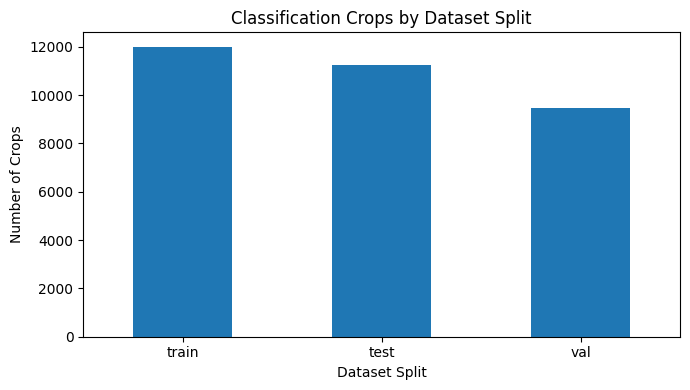

In [3]:

import pandas as pd
import matplotlib.pyplot as plt

# Count crops by dataset split
split_counts = classification_df["split"].value_counts()

print("CLASSIFICATION CROPS BY SPLIT")
print(split_counts)

# Count crops by damage class
class_counts = classification_df["class"].value_counts()

print("\nCLASSIFICATION CROPS BY CLASS")
print(class_counts)

# Show distribution across splits and classes
distribution = pd.crosstab(
    classification_df["class"],
    classification_df["split"]
)

display(distribution)

# Visualise train/validation/test distribution
split_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Classification Crops by Dataset Split")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Crops")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Class Distribution and Dataset Balance Assessment

**Objective:** Evaluate the distribution of road-damage classes (D00, D10, D20, and D40) across the training, validation, and test datasets.

**Methodology:**

- Calculate the number of classification crops belonging to each damage class within each dataset split.
- Calculate the percentage contribution of each class to its respective dataset split.
- Compare class distributions to identify potential class imbalance.

**Interpretation:**

The training dataset contains 3,000 crops per class, resulting in a balanced training distribution of 12,000 crops.

The validation and test datasets retain their naturally occurring class distributions and exhibit class imbalance, particularly for D20 and D40.

**Implications for model development:**

The balanced training dataset supports learning across all four classes, while the validation and test datasets allow performance evaluation under different class distributions.

For M2 and M3, model performance should be assessed using macro-F1, per-class precision and recall, and confusion matrices rather than relying solely on overall accuracy.

In [4]:

# Classification crops by class and split
class_split = pd.crosstab(
    classification_df["class"],
    classification_df["split"]
)

display(class_split)

# Percentage distribution within each split
class_percent = (
    class_split.div(class_split.sum(axis=0), axis=1) * 100
).round(2)

print("Class distribution (%) within each split:")
display(class_percent)


split,test,train,val
class,,,
D00,8570,3000,5092
D10,1730,3000,2758
D20,468,3000,1095
D40,461,3000,518


Class distribution (%) within each split:


split,test,train,val
class,,,
D00,76.32,25.0,53.81
D10,15.41,25.0,29.15
D20,4.17,25.0,11.57
D40,4.11,25.0,5.47


### Country-Based Dataset Splitting and Domain Shift

To evaluate cross-country generalisation and minimise data leakage, the dataset was partitioned by geographical source rather than randomly splitting individual images.

- **Training:** India, Japan, and United States (23,016 images).
- **Validation:** China Drone, China MotorBike, and Czech (7,207 images).
- **Testing:** Norway (8,161 images).

Norway was completely excluded from training and validation, providing an independent country-level holdout for evaluating domain shift.

The seven data sources represent six countries because China contributes two separate image sources.

This splitting strategy allows the classification and detection models to be evaluated on geographically distinct images. The held-out test set must remain excluded from model training, hyperparameter tuning, and model selection.

In [5]:
country_split = pd.crosstab(
    split_df["country"],
    split_df["split"]
)

display(country_split)

split,test,train,val
country,,,
China_Drone,0,0,2401
China_MotorBike,0,0,1977
Czech,0,0,2829
India,0,7706,0
Japan,0,10506,0
Norway-002,8161,0,0
United_States,0,4804,0


### Verification of Norway Test Dataset Annotation Availability

**Objective:** Verify that all images in the geographically held-out Norway test dataset have corresponding XML annotation files.

**Methodology:**
1. Filter the dataset manifest to select Norway test images.
2. Check whether each corresponding XML annotation file exists.
3. Calculate the total number of available and missing annotation files.
4. Display sample annotation paths for verification.

**Results:**
- Total Norway test images: 8,161
- Available XML annotation files: 8,161
- Missing XML annotation files: 0
- Annotation file availability: 100%

**Conclusion:** All 8,161 Norway test images have corresponding XML annotation files available, supporting the use of this labelled dataset for independent evaluation of model performance and domain shift.

In [6]:
from pathlib import Path
import pandas as pd

norway_test = split_df[
    (split_df["country"] == "Norway-002") &
    (split_df["split"] == "test")
].copy()    

norway_test["xml_exists"] = norway_test["xml_path"].apply(
    lambda p: Path(str(p)).is_file() if pd.notna(p) else False
)

print("Norway test images:", len(norway_test))
print("XML files found:", norway_test["xml_exists"].sum())
print("XML files missing:", (~norway_test["xml_exists"]).sum())

print("\nExample annotation paths:")
for path in norway_test["xml_path"].head(3):
    print(repr(path))

Norway test images: 8161
XML files found: 8161
XML files missing: 0

Example annotation paths:
'C:\\Users\\abdul\\OneDrive\\سطح المكتب\\AI CAUST\\Appled computer vision\\Capston project\\data\\Images\\Norway-002\\Norway\\train\\annotations\\xmls\\Norway_000000.xml'
'C:\\Users\\abdul\\OneDrive\\سطح المكتب\\AI CAUST\\Appled computer vision\\Capston project\\data\\Images\\Norway-002\\Norway\\train\\annotations\\xmls\\Norway_000001.xml'
'C:\\Users\\abdul\\OneDrive\\سطح المكتب\\AI CAUST\\Appled computer vision\\Capston project\\data\\Images\\Norway-002\\Norway\\train\\annotations\\xmls\\Norway_000002.xml'


### XML Annotation Integrity and Class Distribution Verification

**Objective:** Validate the readability of XML annotation files in the held-out Norway test dataset and examine the distribution of road-damage classes.

**Methodology:**
1. Parse all Norway test XML files using Python's ElementTree library.
2. Identify readable and unreadable XML files.
3. Extract object-level damage labels from each XML file.
4. Count the annotations belonging to each road-damage category.

**Results:**
- Total readable XML files: 8,161
- Unreadable XML files: 0
- XML parsing success rate: 100%
- Total damage annotations: 11,229

**Class Distribution:**
- D00 (Longitudinal cracks): 8,570
- D10 (Transverse cracks): 1,730
- D20 (Alligator cracks): 468
- D40 (Potholes): 461

**Interpretation:** All XML files were successfully parsed, confirming their structural readability. However, the annotation distribution is imbalanced, with longitudinal cracks substantially more frequent than other damage categories.

**Conclusion:** The Norway test dataset has readable XML annotations for all images and can support evaluation of classification performance across four damage classes. Macro-averaged F1-score, per-class precision, recall, and confusion matrices should be reported to account for class imbalance.

In [7]:
import xml.etree.ElementTree as ET
from collections import Counter

label_counts = Counter()
valid_xml = 0
invalid_xml = 0

for path in norway_test["xml_path"]:
    try:
        root = ET.parse(path).getroot()
        valid_xml += 1

        for obj in root.findall(".//object"):
            name = obj.findtext("name")
            if name:
                label_counts[name] += 1

    except (ET.ParseError, OSError):
        invalid_xml += 1

print("Readable XML files:", valid_xml)
print("Unreadable XML files:", invalid_xml)
print("Damage annotations:", dict(label_counts))

Readable XML files: 8161
Unreadable XML files: 0
Damage annotations: {'D00': 8570, 'D20': 468, 'D40': 461, 'D10': 1730}


### Cross-Split Duplicate Candidate Group Analysis

**Objective:** Assess the distribution of potential duplicate-image groups across training, validation, and test splits to identify possible data leakage.

**Methodology:**
1. Group candidate images using their assigned `candidate_group` identifiers.
2. Calculate the number of images within each candidate group.
3. Determine how many distinct dataset splits each group spans.
4. Identify groups containing images from multiple dataset splits.
5. Display the first ten candidate groups for inspection.

**Results:**
- Total candidate groups: 388
- Candidate groups crossing dataset splits: 388
- Candidate groups confined to one split: 0

**Interpretation:** All identified candidate groups contain images from at least two dataset splits. However, similarity-based grouping does not establish that the images are genuine duplicates. Similar road surfaces, textures, and damage patterns may produce false-positive duplicate candidates.

**Conclusion:** The analysis identifies 388 cross-split candidate groups requiring consideration in the data leakage assessment. Manual verification and exact-duplicate checks are necessary to distinguish actual duplication from visual similarity.

In [8]:
# Identify candidate groups spanning multiple splits
group_summary = review_df.groupby("candidate_group").agg(
    image_count=("image_id", "nunique"),
    split_count=("split", "nunique"),
    splits=("split", lambda x: ", ".join(sorted(x.unique())))
)

cross_split_groups = group_summary[
    group_summary["split_count"] > 1
]

print("Total candidate groups:",
      len(group_summary))

print("Groups crossing dataset splits:",
      len(cross_split_groups))

print("Groups within one split:",
      len(group_summary) - len(cross_split_groups))

display(cross_split_groups.head(10))

NameError: name 'review_df' is not defined

### Manual Verification of Potential Cross-Split Duplicates

**Objective:** Validate potential duplicate-image pairs identified during the data leakage assessment.

**Methodology:**
- Load the manual review decisions from `ranked_pair_review_decisions.csv`.
- Review 50 selected image pairs, consisting of 30 highest-ranked similarity candidates and 20 randomly selected remaining candidates.
- Record the classification status and supporting observations for each reviewed pair.
- Inspect the review records to document potential cross-split duplication.

**Results:**
- Total reviewed pairs: 50
- Highest-ranked candidates: 30
- Randomly selected candidates: 20
- Pairs classified as different scenes: 50
- Confirmed duplicates among reviewed pairs: 0

**Interpretation:** All 50 reviewed image pairs were classified as different road scenes based on visual characteristics, including road layout, markings, and surrounding environments.

**Conclusion:** No confirmed duplicates were identified among the 50 manually reviewed pairs. These findings support the initial leakage assessment, although they do not exclude possible duplicates among unreviewed candidates.

In [ ]:
import pandas as pd

decision_path = (
    PROJECT_ROOT
    / "reports"
    / "m1"
    / "ranked_pair_review_decisions.csv"
)

decisions = pd.read_csv(decision_path)

print("Total reviewed records:", len(decisions))
print("\nColumns:")
print(decisions.columns.tolist())

display(decisions.head(10))

Total reviewed records: 50

Columns:
['pair_id', 'sheet', 'image_a', 'image_b', 'selection', 'status', 'notes']


,pair_id,sheet,image_a,image_b,selection,status,notes
0,1,pair_001.jpg,India_India_008504,Norway-002_Norway_006750,highest_ranked,different_scenes,Different road layout and surroundings
1,2,pair_002.jpg,India_India_001565,Norway-002_Norway_004824,highest_ranked,different_scenes,Different road layout and surroundings
2,3,pair_003.jpg,India_India_001565,Norway-002_Norway_006473,highest_ranked,different_scenes,Different road layout and surroundings
3,4,pair_004.jpg,India_India_001565,Norway-002_Norway_005690,highest_ranked,different_scenes,Different road layout and surroundings
4,5,pair_005.jpg,India_India_001565,Norway-002_Norway_002559,highest_ranked,different_scenes,Different road markings and surroundings
5,6,pair_006.jpg,Japan_Japan_005364,Norway-002_Norway_005869,highest_ranked,different_scenes,Different road layout and surroundings
6,7,pair_007.jpg,India_India_003410,Norway-002_Norway_003155,highest_ranked,different_scenes,Different road layout and surroundings
7,8,pair_008.jpg,India_India_003410,Norway-002_Norway_006407,highest_ranked,different_scenes,Different road layout and surroundings
8,9,pair_009.jpg,India_India_006419,Norway-002_Norway_001950,highest_ranked,different_scenes,Different road layout and surroundings
9,10,pair_010.jpg,Japan_Japan_005364,Norway-002_Norway_006473,highest_ranked,different_scenes,Different road layout and surroundings


### Cross-Split Data Leakage Assessment

A duplicate-screening procedure was performed to identify potentially overlapping images across the training, validation, and test datasets.

**Results:**
- 388 candidate groups were flagged for potential cross-split similarity.
- 50 image pairs were manually reviewed.
- 30 pairs were selected from the highest-ranked similarity candidates.
- 20 additional pairs were randomly selected.
- All 50 reviewed pairs were classified as different road scenes.
- No confirmed duplicates were identified among the reviewed pairs.

**Conclusion:**

The manual review did not identify confirmed data leakage among the inspected pairs. However, unreviewed similarity candidates remain, so the absence of leakage across the entire dataset cannot yet be guaranteed.

The country-level split was maintained to support domain-shift evaluation.

In [ ]:
print("DUPLICATE REVIEW SUMMARY")
print("-" * 40)

print("Total reviewed pairs:", len(decisions))

print("\nDecision status:")
print(decisions["status"].value_counts(dropna=False))

print("\nSelection method:")
print(decisions["selection"].value_counts(dropna=False))

print("\nUnreviewed or uncertain decisions:")
uncertain = decisions[
    decisions["status"].isna()
    | decisions["status"].astype(str).str.contains(
        "review|uncertain|pending",
        case=False,
        regex=True
    )
]

display(uncertain)

DUPLICATE REVIEW SUMMARY
----------------------------------------
Total reviewed pairs: 50

Decision status:
status
different_scenes    50
Name: count, dtype: int64

Selection method:
selection
highest_ranked      30
random_remaining    20
Name: count, dtype: int64

Unreviewed or uncertain decisions:


,pair_id,sheet,image_a,image_b,selection,status,notes


### Classification Crop Dataset — Metadata Validation

**Objective:** Verify the completeness, class distribution, and dataset split distribution of the generated classification crops.

**Results:**
- Total classification crops: **32,692**
- Training crops: 12,000
- Validation crops: 9,463
- Test crops: 11,229
- Missing metadata values: 0
- Damage classes: D00, D10, D20, D40

**Observations:**
- All crop records contain the required metadata fields: `crop_path`, `image_id`, `split`, and `class`.
- D00 is the most represented class, indicating class imbalance.
- The dataset contains all three required splits.

**Conclusion:** The classification crop metadata is complete. Further verification is required to confirm that all crop images are readable and that their labels and splits match the original annotations and source images.

In [ ]:
from pathlib import Path
from PIL import Image
import pandas as pd

print("Available columns:")
print(classification_df.columns.tolist())

print("\nTotal classification records:")
print(len(classification_df))

print("\nMissing values:")
print(classification_df.isna().sum())

print("\nClass distribution:")
print(classification_df["class"].value_counts())

print("\nSplit distribution:")
print(classification_df["split"].value_counts())

Available columns:
['crop_path', 'image_id', 'split', 'class']

Total classification records:
32692

Missing values:
crop_path    0
image_id     0
split        0
class        0
dtype: int64

Class distribution:
class
D00    16662
D10     7488
D20     4563
D40     3979
Name: count, dtype: int64

Split distribution:
split
train    12000
test     11229
val       9463
Name: count, dtype: int64


### Classification Crop Integrity Verification

**Objective:** Verify the integrity and accessibility of all generated classification crops before model training.

**Validation criteria:**
- Confirm that every crop file exists at its recorded path.
- Verify that crop images can be opened and decoded successfully.
- Detect empty or corrupted image files.
- Validate class labels against the four expected categories: D00, D10, D20, and D40.

**Expected outcome:** All 32,692 classification crop records should pass the integrity checks, with zero missing files, unreadable images, or invalid class names.

**Note:** This verification checks file integrity and valid class names. It does not independently confirm that crop labels match their original XML annotations.

In [ ]:

from pathlib import Path
from PIL import Image
from collections import Counter

results = Counter()
problem_files = []

valid_classes = {"D00", "D10", "D20", "D40"}

for crop_path, image_id, split, class_name in classification_df[
    ["crop_path", "image_id", "split", "class"]
].itertuples(index=False, name=None):

    path = Path(str(crop_path))

    if class_name not in valid_classes:
        results["invalid_class"] += 1
        problem_files.append((str(path), "Invalid class"))
        continue

    if not path.is_file():
        results["missing_file"] += 1
        problem_files.append((str(path), "Missing file"))
        continue

    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            img.load()
            if img.width <= 0 or img.height <= 0:
                raise ValueError("Empty image")

        results["valid_crops"] += 1

    except Exception as e:
        results["unreadable_crop"] += 1
        problem_files.append((str(path), str(e)))

print("CROP VERIFICATION SUMMARY")
print("-" * 40)
print("Total records:", len(classification_df))
print("Valid crops:", results["valid_crops"])
print("Missing files:", results["missing_file"])
print("Unreadable crops:", results["unreadable_crop"])
print("Invalid classes:", results["invalid_class"])

print("\nExample problems:")
print(problem_files[:10])


CROP VERIFICATION SUMMARY
----------------------------------------
Total records: 32692
Valid crops: 0
Missing files: 32692
Unreadable crops: 0
Invalid classes: 0

Example problems:
[('data\\processed\\classification_crops\\test\\D00\\Norway-002_Norway_002630_0.jpg', 'Missing file'), ('data\\processed\\classification_crops\\test\\D00\\Norway-002_Norway_004309_2.jpg', 'Missing file'), ('data\\processed\\classification_crops\\test\\D00\\Norway-002_Norway_000809_6.jpg', 'Missing file'), ('data\\processed\\classification_crops\\test\\D00\\Norway-002_Norway_001862_0.jpg', 'Missing file'), ('data\\processed\\classification_crops\\test\\D00\\Norway-002_Norway_007772_0.jpg', 'Missing file'), ('data\\processed\\classification_crops\\test\\D00\\Norway-002_Norway_000027_0.jpg', 'Missing file'), ('data\\processed\\classification_crops\\test\\D00\\Norway-002_Norway_004092_0.jpg', 'Missing file'), ('data\\processed\\classification_crops\\test\\D00\\Norway-002_Norway_007384_26.jpg', 'Missing file'), 

### Final Classification Crop Leakage Verification

**Objective:** Verify that classification crops preserve the dataset split assignments of their original source images.

**Methodology:**
- Match each classification crop to its original image using `image_id`.
- Compare the crop split against the original image split.
- Identify missing parent-image references.
- Detect original images whose crops appear across multiple splits.

**Acceptance criteria:**
- Zero unmatched original images.
- Zero crop-to-original split mismatches.
- Zero original image IDs appearing across multiple crop splits.

**Interpretation:** Passing these checks confirms that classification crop generation preserves the original image-level split assignments. Potential visual similarities between different source images remain a separate leakage consideration.

In [ ]:

import pandas as pd

manifest_path = PROJECT_ROOT / "data" / "processed" / "split_manifest.csv"
manifest = pd.read_csv(manifest_path)

original_splits = manifest[["image_id", "split"]].drop_duplicates()

comparison = classification_df.merge(
    original_splits,
    on="image_id",
    how="left",
    suffixes=("_crop", "_original"),
    validate="many_to_one",
    indicator=True
)

missing_parents = comparison["_merge"].eq("left_only")

split_mismatch = (
    comparison["split_original"].notna()
    & comparison["split_crop"].ne(comparison["split_original"])
)

print("FINAL CROP LEAKAGE VERIFICATION")
print("-" * 40)
print("Total crops:", len(comparison))
print("Crops without matching original image:", missing_parents.sum())
print("Crops with incorrect split:", split_mismatch.sum())

print("\nOriginal image IDs appearing in multiple crop splits:")
cross_split = (
    classification_df.groupby("image_id")["split"]
    .nunique()
)
print((cross_split > 1).sum())

print("\nExamples of split mismatches:")
display(comparison[split_mismatch].head(10))


FINAL CROP LEAKAGE VERIFICATION
----------------------------------------
Total crops: 32692
Crops without matching original image: 0
Crops with incorrect split: 0

Original image IDs appearing in multiple crop splits:
0

Examples of split mismatches:


,crop_path,image_id,split_crop,class,split_original,_merge


### Residual Similarity Risk and Manual Review

**Objective:** Evaluate potential cross-split image similarities and document the results of manual duplicate verification.

**Methodology:**
- Identify perceptually similar images across training, validation, and test datasets.
- Group potential duplicate candidates for further investigation.
- Manually review 50 selected image pairs, consisting of 30 highest-ranked candidates and 20 randomly selected remaining candidates.
- Classify reviewed pairs based on road layout, markings, and surrounding environments.

**Results:**
- Cross-split similarity candidate groups: **388**
- Candidate image records: **3,469**
- Manually reviewed image pairs: **50**
- Highest-ranked pairs reviewed: **30**
- Randomly selected pairs reviewed: **20**
- Pairs classified as different scenes: **50**
- Confirmed duplicates among reviewed pairs: **0**

**Limitations:** Manual verification covered only 50 selected image pairs. The remaining similarity candidates were not exhaustively reviewed, and potential near-duplicate leakage cannot be completely excluded.

**Conclusion:** No confirmed duplicates were identified among the 50 manually reviewed pairs. The original image-level and classification crop-level split checks also passed. Residual similarity risk remains documented for future investigation.

In [ ]:

import pandas as pd

# Load similarity candidates
candidate_path = (
    PROJECT_ROOT / "reports" / "m1"
    / "cross_split_candidates.csv"
)

# Load manual review decisions
decision_path = (
    PROJECT_ROOT / "reports" / "m1"
    / "ranked_pair_review_decisions.csv"
)

candidates = pd.read_csv(candidate_path)
decisions = pd.read_csv(decision_path)

# Summarise candidate groups
total_groups = candidates["candidate_group"].nunique()
total_records = len(candidates)

# Summarise manual review
total_reviewed = len(decisions)
review_status = decisions["status"].value_counts()
selection_counts = decisions["selection"].value_counts()

print("FINAL SIMILARITY REVIEW SUMMARY")
print("-" * 45)

print("Candidate groups:", total_groups)
print("Candidate image records:", total_records)
print("Manually reviewed pairs:", total_reviewed)

print("\nReview decisions:")
print(review_status.to_string())

print("\nSelection methods:")
print(selection_counts.to_string())

# Identify unresolved candidate groups
print("\nIMPORTANT:")
print(
    "Manual review covers selected image pairs, "
    "not necessarily all candidate groups or pairs."
)


FINAL SIMILARITY REVIEW SUMMARY
---------------------------------------------
Candidate groups: 388
Candidate image records: 3469
Manually reviewed pairs: 50

Review decisions:
status
different_scenes    50

Selection methods:
selection
highest_ranked      30
random_remaining    20

IMPORTANT:
Manual review covers selected image pairs, not necessarily all candidate groups or pairs.
